# Etapa 1 — Ingestão de Dados

Este notebook coleta e persiste, em Parquet, todas as fontes de dados do projeto:

1. **Calendário do Copom** — construído a partir da API institucional do BCB (não é o Olinda/OData). É a base de tudo o que segue, porque resolve o mapeamento entre `Reuniao` (`"R6/2026"`) do Focus e uma data de calendário real.
2. **Expectativas Focus** — mediana e Top 5 para **cinco indicadores**: IPCA, Câmbio, IGP-M e Taxa de desocupação (mensais) mais a Selic (por reunião).
3. **Séries realizadas (SGS)** — o "gabarito" de cada indicador, mais IBC-Br, IC-Br e meta de inflação usados como features.
4. **Mercado externo** — USD/BRL e Treasury de 10 anos dos EUA (`yfinance`).

## Achados críticos da API (validados ao vivo antes de escrever este pipeline)

Estes pontos **contradizem** o que normalmente se encontra em referências rápidas sobre a API do BCB — se você está adaptando este notebook, preste atenção:

- O endpoint mensal correto é **`ExpectativaMercadoMensais`** (singular). A grafia `ExpectativasMercadoMensais` (com "s" em "Expectativas") retorna **HTTP 400**.
- A **Selic não existe** no endpoint mensal — `Indicador eq 'Selic'` ali retorna lista vazia. Ela mora em `ExpectativasMercadoSelic`, chaveada por **reunião do Copom**, não por mês.
- O campo `baseCalculo` gera **duas linhas por (Data, DataReferencia)** — 30 dias corridos (`0`) vs. 5 dias úteis (`1`). Sem filtrar, o painel dobra silenciosamente.
- A caixa dos nomes de campo **não é consistente entre entidades**: `ExpectativasMercadoTop5Selic` devolve `indicador`/`reuniao`/`mediana` em minúsculas, enquanto as demais usam `Indicador`/`Reuniao`/`Mediana`.
- O parser OData do BCB tem uma peculiaridade: ele **rejeita espaços codificados como `+`** (a codificação padrão de `requests` para parâmetros) no `$filter`, devolvendo um erro opaco (`"Edm.Boolean and Edm.String not compatible"`). É necessário forçar `%20`. Isso já está corrigido em `src/focus/rede.py`.

## A convenção do Câmbio: uma decisão empírica, não uma suposição

O Focus projeta "Câmbio" para um mês de referência — mas **não documenta se isso é a cotação média do mês ou a de fim de período**. Escolher a série errada do SGS não produziria um erro óbvio: produziria um viés plausível, que seria silenciosamente atribuído ao Focus.

Resolvemos isso medindo. Comparando a mediana do Focus contra as duas candidatas ao longo de 2015–2026:

| Série | h=1 MAE | h=3 MAE |
|---|---|---|
| **SGS 3698 — média mensal** | **0,1245** | **0,2362** |
| SGS 3695 — fim de período | 0,1694 | 0,2716 |

A média mensal vence com folga em ambos os horizontes (MAE 26% menor em h=1). **O Focus projeta a média do mês.** Usar fim de período teria inflado artificialmente o erro atribuído ao Focus em mais de um quarto — o mesmo tipo de armadilha da vigência prospectiva da SGS 432, que quase contaminou o painel da Selic.

## Por que o calendário do Copom vem primeiro

O plano original desta análise previa manter um CSV com o calendário de reuniões do Copom, mantido manualmente. Isso se mostrou desnecessário: a API `historicotaxasjuros` do próprio site do BCB devolve o histórico completo de decisões (data, número da reunião, meta Selic decidida), o que permite **derivar programaticamente** o rótulo `Rn/AAAA` usado pelo Focus. A partir de 2006 há exatamente 8 reuniões ordinárias por ano e nenhuma reunião extraordinária no histórico — por isso o rótulo é simplesmente o rank da reunião dentro do ano.

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

RAIZ_PROJETO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ_PROJETO / "src"))

from focus.configuracao import (
    AMOSTRA_INICIO,
    DIR_BRUTO,
    DIR_REFERENCIA,
    INDICADORES_MENSAIS,
    SERIES_SGS,
    TICKERS_MERCADO,
)
from focus.copom import construir_calendario_copom, validar_calendario_copom
from focus.ingest_focus import (
    buscar_focus_mensal,
    buscar_focus_selic,
    buscar_focus_top5_mensal,
    buscar_focus_top5_selic,
)
from focus.ingest_sgs import buscar_serie_sgs
from focus.ingest_market import buscar_ticker_yfinance
from focus.armazenamento import obter_ou_buscar, resumo_manifesto

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print(f"Início da amostra: {AMOSTRA_INICIO}")
print(f"Diretório de dados brutos: {DIR_BRUTO.relative_to(RAIZ_PROJETO).as_posix()}")

Início da amostra: 2006-01-01
Diretório de dados brutos: dados/bruto


## 1. Calendário do Copom

Base para todo o painel de Selic e para as flags de regime (pivot, ciclo de aperto/afrouxamento) construídas na Etapa 2.

In [2]:
calendario_copom = obter_ou_buscar(
    DIR_REFERENCIA, "calendario_copom",
    fonte="https://www.bcb.gov.br/api/servico/sitebcb/historicotaxasjuros",
    funcao_busca=lambda: construir_calendario_copom(AMOSTRA_INICIO),
    coluna_data="data_reuniao",
)
print(f"{len(calendario_copom)} reuniões ordinárias desde {AMOSTRA_INICIO}")
calendario_copom.head(3)

166 reuniões ordinárias desde 2006-01-01


,rotulo_reuniao,numero_reuniao,data_reuniao,meta_selic,vies,ano,rank_no_ano
0,R1/2006,116.0,2006-01-18,17.25,sem viés,2006,1
1,R2/2006,117.0,2006-03-08,16.50,sem viés,2006,2
2,R3/2006,118.0,2006-04-19,15.75,sem viés,2006,3


In [3]:
# Validação de sanidade: todo ano civil COMPLETO deve ter exatamente 8 reuniões.
resultado_validacao = validar_calendario_copom(calendario_copom)
anos_com_erro = resultado_validacao["anos_com_contagem_errada"]

assert not anos_com_erro, f"Contagem de reuniões inesperada nos anos: {anos_com_erro}"
print("OK: todo ano completo tem exatamente 8 reuniões ordinárias do Copom.")

pd.Series(resultado_validacao["contagem_por_ano"], name="reuniões").to_frame().T

OK: todo ano completo tem exatamente 8 reuniões ordinárias do Copom.


,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
reuniões,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,6


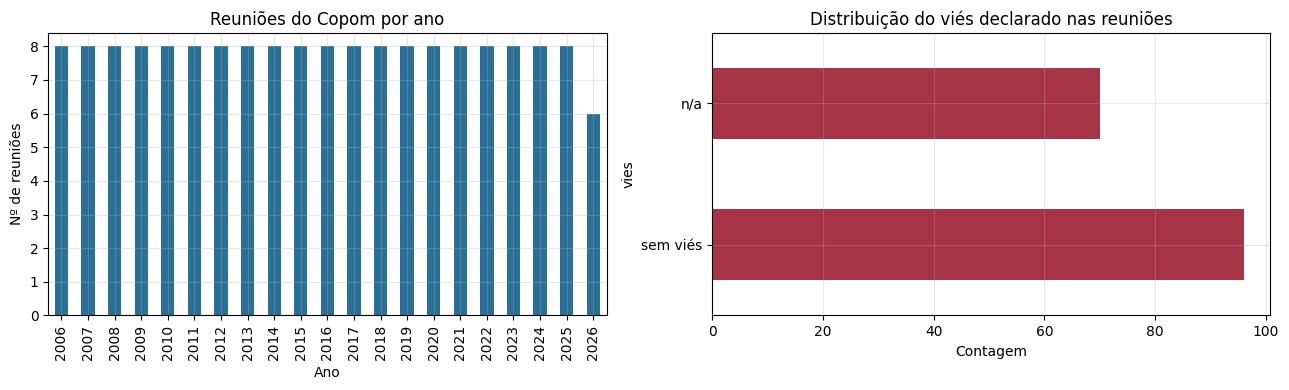

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

calendario_copom.groupby("ano").size().plot(kind="bar", ax=ax1, color="#2a6f97")
ax1.set_title("Reuniões do Copom por ano")
ax1.set_xlabel("Ano")
ax1.set_ylabel("Nº de reuniões")

calendario_copom["vies"].value_counts().plot(kind="barh", ax=ax2, color="#a63446")
ax2.set_title("Distribuição do viés declarado nas reuniões")
ax2.set_xlabel("Contagem")

plt.tight_layout()
plt.show()

## 2. Expectativas Focus — cinco indicadores

Quatro indicadores **mensais** (IPCA, Câmbio, IGP-M, Taxa de desocupação) mais a **Selic**, que é o caso à parte por ser chaveada por reunião do Copom em vez de por mês.

A escolha dos indicadores não é arbitrária: eles cobrem propositalmente regimes de previsibilidade muito diferentes — o **Câmbio** é quase um passeio aleatório (notoriamente difícil de prever), a **Taxa de desocupação** é inercial e suave (deve ser fácil), o **IGP-M** é volátil e sensível a câmbio/commodities, e o **IPCA** fica no meio. Esse contraste é o que permite responder "qual é a qualidade da projeção *dos indicadores*" com alguma generalidade, em vez de uma conclusão presa a um único caso.

Cada extração é fatiada por ano civil (ver `src/focus/odata.py`); a primeira execução leva alguns minutos, reexecuções são baratas pelo cache de manifesto.

In [5]:
%%time
focus_mensal, focus_top5_mensal = {}, {}

for indicador, cfg in INDICADORES_MENSAIS.items():
    nome = cfg["nome"]
    focus_mensal[nome] = obter_ou_buscar(
        DIR_BRUTO, f"focus_{nome}_mensal",
        fonte=f"Olinda OData (ExpectativaMercadoMensais / {indicador})",
        funcao_busca=lambda ind=indicador: buscar_focus_mensal(ind, AMOSTRA_INICIO),
        coluna_data="data_pesquisa",
    )
    focus_top5_mensal[nome] = obter_ou_buscar(
        DIR_BRUTO, f"focus_{nome}_top5_mensal",
        fonte=f"Olinda OData (ExpectativasMercadoTop5Mensais / {indicador})",
        funcao_busca=lambda ind=indicador: buscar_focus_top5_mensal(ind, AMOSTRA_INICIO),
        coluna_data="data_pesquisa",
    )
    print(f"{indicador:<22} mediana={len(focus_mensal[nome]):>7,}  top5={len(focus_top5_mensal[nome]):>7,}")

IPCA                   mediana= 99,229  top5= 98,440
Câmbio                 mediana= 97,801  top5= 69,553
IGP-M                  mediana= 89,257  top5= 67,771
Taxa de desocupação    mediana= 22,572  top5=      0
CPU times: total: 406 ms
Wall time: 223 ms


In [6]:
%%time
focus_selic = obter_ou_buscar(
    DIR_BRUTO, "focus_selic", fonte="Olinda OData (ExpectativasMercadoSelic)",
    funcao_busca=lambda: buscar_focus_selic(AMOSTRA_INICIO), coluna_data="data_pesquisa",
)
focus_top5_selic = obter_ou_buscar(
    DIR_BRUTO, "focus_top5_selic", fonte="Olinda OData (ExpectativasMercadoTop5Selic)",
    funcao_busca=lambda: buscar_focus_top5_selic(AMOSTRA_INICIO), coluna_data="data_pesquisa",
)
print(f"Selic (por reunião)    mediana={len(focus_selic):>7,}  top5={len(focus_top5_selic):>7,}")

Selic (por reunião)    mediana= 65,022  top5= 64,985


CPU times: total: 46.9 ms
Wall time: 51 ms


### EDA de qualidade de dados — cobertura e nº de respondentes

Checamos que a cobertura temporal é contínua (sem "buracos" de meses/reuniões) e como o número de respondentes evoluiu por indicador — uma queda abrupta costuma indicar problema de extração, não um fenômeno real. Já sabemos de uma quebra estrutural legítima: o campo `numeroRespondentes` só é preenchido pela API a partir de 2014.

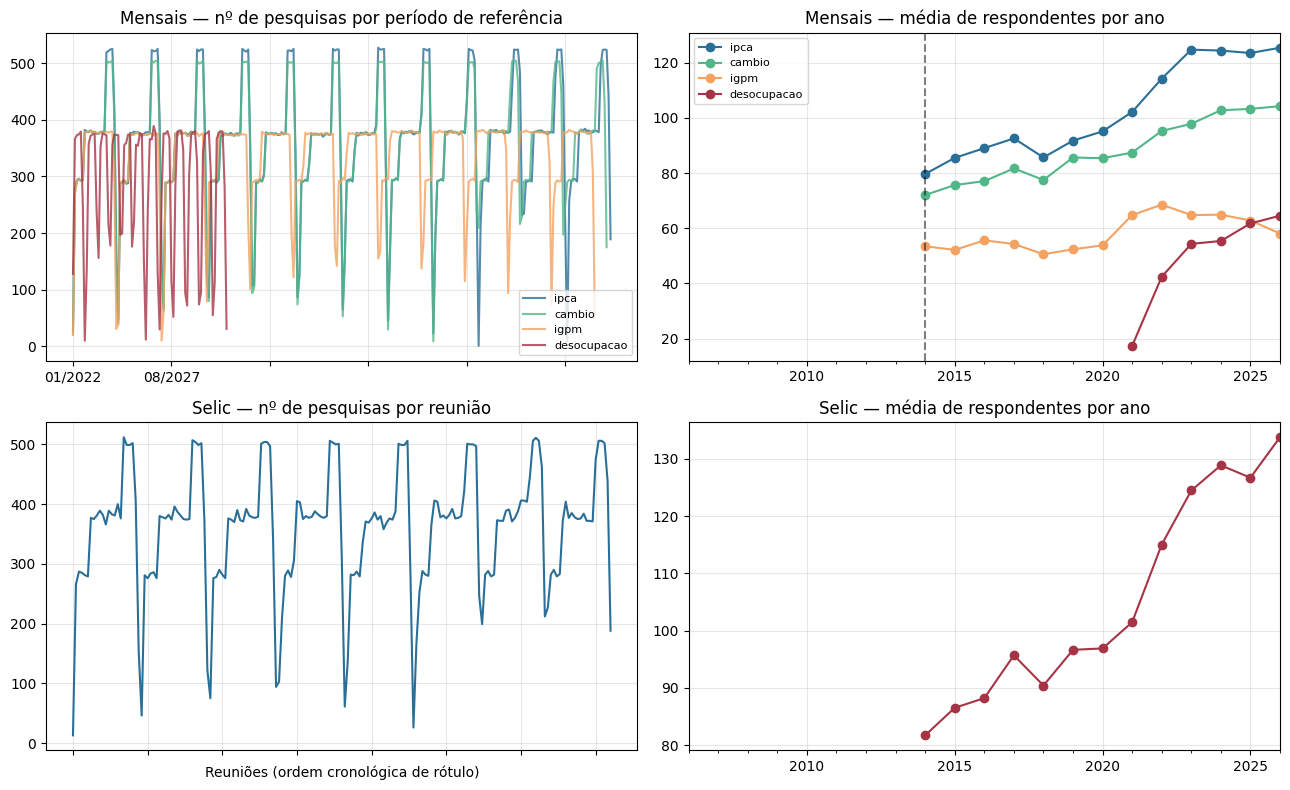

In [7]:
CORES_IND = {"ipca": "#2a6f97", "cambio": "#52b788", "igpm": "#f4a261", "desocupacao": "#a63446"}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for nome, df in focus_mensal.items():
    df.groupby("referencia").size().plot(ax=axes[0, 0], color=CORES_IND[nome], label=nome, alpha=0.8)
axes[0, 0].set_title("Mensais — nº de pesquisas por período de referência")
axes[0, 0].set_xlabel("")
axes[0, 0].legend(fontsize=8)

for nome, df in focus_mensal.items():
    (df.set_index("data_pesquisa")["num_respondentes"].resample("YE").mean()
       .plot(ax=axes[0, 1], color=CORES_IND[nome], marker="o", label=nome))
axes[0, 1].axvline(pd.Timestamp("2014-01-01"), color="black", linestyle="--", alpha=0.5)
axes[0, 1].set_title("Mensais — média de respondentes por ano")
axes[0, 1].set_xlabel("")
axes[0, 1].legend(fontsize=8)

focus_selic.groupby("reuniao").size().plot(ax=axes[1, 0], color="#2a6f97", rot=90)
axes[1, 0].set_title("Selic — nº de pesquisas por reunião")
axes[1, 0].set_xticklabels([])
axes[1, 0].set_xlabel("Reuniões (ordem cronológica de rótulo)")

focus_selic.set_index("data_pesquisa")["num_respondentes"].resample("YE").mean().plot(
    ax=axes[1, 1], color="#a63446", marker="o"
)
axes[1, 1].set_title("Selic — média de respondentes por ano")
axes[1, 1].set_xlabel("")

plt.tight_layout()
plt.show()

In [8]:
# Sanidade: nenhuma chave duplicada em nenhum dataset Focus
checagens = []
for nome, df in focus_mensal.items():
    checagens.append((f"focus_{nome}_mensal", df, ["data_pesquisa", "referencia"]))
for nome, df in focus_top5_mensal.items():
    checagens.append((f"focus_{nome}_top5_mensal", df, ["data_pesquisa", "referencia"]))
checagens.append(("focus_selic", focus_selic, ["data_pesquisa", "reuniao"]))
checagens.append(("focus_top5_selic", focus_top5_selic, ["data_pesquisa", "reuniao"]))

for nome, df, chaves in checagens:
    n_dup = df.duplicated(subset=chaves).sum()
    print(f"{nome:<28} {len(df):>8,} linhas | duplicatas: {n_dup}")
    assert n_dup == 0, f"{nome} tem chaves duplicadas!"

print()
print(f"OK: nenhuma chave duplicada em nenhum dos {len(checagens)} datasets Focus.")

focus_ipca_mensal              99,229 linhas | duplicatas: 0
focus_cambio_mensal            97,801 linhas | duplicatas: 0
focus_igpm_mensal              89,257 linhas | duplicatas: 0
focus_desocupacao_mensal       22,572 linhas | duplicatas: 0
focus_ipca_top5_mensal         98,440 linhas | duplicatas: 0
focus_cambio_top5_mensal       69,553 linhas | duplicatas: 0
focus_igpm_top5_mensal         67,771 linhas | duplicatas: 0
focus_desocupacao_top5_mensal        0 linhas | duplicatas: 0
focus_selic                    65,022 linhas | duplicatas: 0
focus_top5_selic               64,985 linhas | duplicatas: 0

OK: nenhuma chave duplicada em nenhum dos 10 datasets Focus.


## 3. Séries realizadas (SGS)

IPCA mensal, Meta Selic diária, IBC-Br, IC-Br e meta de inflação. Buscamos com **2 anos de margem antes** do início da amostra, porque as features de momento (3m/6m) e revisão precisam de histórico anterior para não nascer com `NaN` logo nos primeiros meses do painel.

In [9]:
%%time
# 2 anos de margem antes do inicio da amostra: momentos (3m/6m) e revisoes
# precisam de historico anterior para nao nascer com NaN nos primeiros meses.
inicio_com_margem = (pd.Timestamp(AMOSTRA_INICIO) - pd.DateOffset(years=2)).strftime("%Y-%m-%d")

series_sgs = {}
for codigo, (nome, _e_diaria) in SERIES_SGS.items():
    series_sgs[nome] = obter_ou_buscar(
        DIR_BRUTO, f"sgs_{nome}", fonte=f"SGS/BCB (codigo {codigo})",
        funcao_busca=lambda c=codigo: buscar_serie_sgs(c, inicio_com_margem), coluna_data="data",
    )
    df = series_sgs[nome]
    print(f"{nome:30s} {len(df):>6,} linhas | {df['data'].min().date()} -> {df['data'].max().date()}")

ipca_mensal                       272 linhas | 2004-01-01 -> 2026-08-01


meta_selic                      8,298 linhas | 2004-01-01 -> 2026-09-19


selic_acum_mes_anualizada         273 linhas | 2004-01-01 -> 2026-09-01


ibcbr                             271 linhas | 2004-01-01 -> 2026-07-01


icbr                              272 linhas | 2004-01-01 -> 2026-08-01


meta_inflacao                      23 linhas | 2004-01-01 -> 2026-01-01


igpm                              272 linhas | 2004-01-01 -> 2026-08-01


cambio                            272 linhas | 2004-01-01 -> 2026-08-01


desocupacao                       173 linhas | 2012-03-01 -> 2026-07-01
CPU times: total: 531 ms
Wall time: 2min 40s


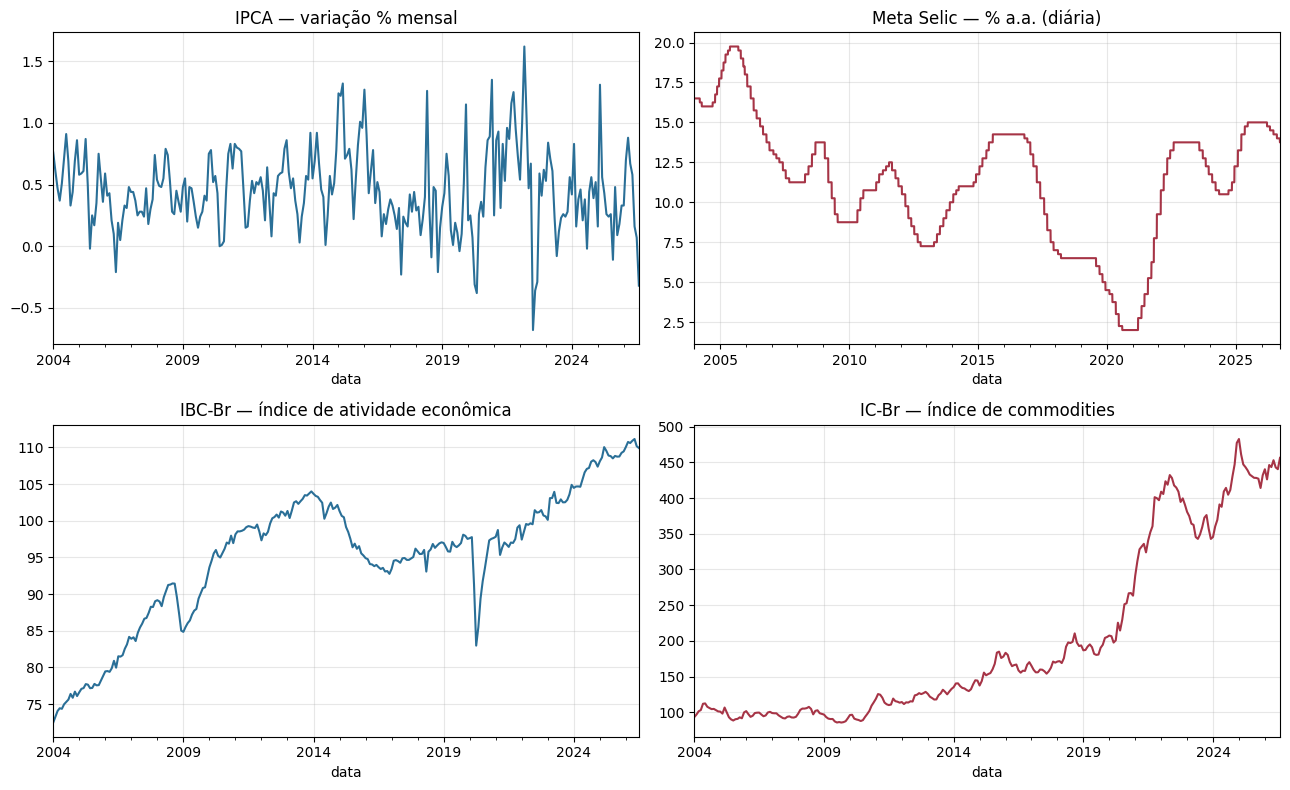

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

series_sgs["ipca_mensal"].set_index("data")["valor"].plot(ax=axes[0, 0], color="#2a6f97")
axes[0, 0].set_title("IPCA — variação % mensal")

series_sgs["meta_selic"].set_index("data")["valor"].plot(ax=axes[0, 1], color="#a63446")
axes[0, 1].set_title("Meta Selic — % a.a. (diária)")

series_sgs["ibcbr"].set_index("data")["valor"].plot(ax=axes[1, 0], color="#2a6f97")
axes[1, 0].set_title("IBC-Br — índice de atividade econômica")

series_sgs["icbr"].set_index("data")["valor"].plot(ax=axes[1, 1], color="#a63446")
axes[1, 1].set_title("IC-Br — índice de commodities")

plt.tight_layout()
plt.show()

## 4. Mercado externo (USD/BRL, Treasury 10 anos)

Mantido em granularidade **diária** propositalmente — o alinhamento com a data de travamento da pesquisa Focus é feito por junção *as-of* na Etapa 2, nunca por reamostragem aqui (reamostrar agora destruiria a propriedade *point-in-time* do painel).

In [11]:
%%time
def _buscar_e_formatar_ticker(ticker):
    bruto = buscar_ticker_yfinance(ticker)
    return bruto[["data", "Close"]].rename(columns={"Close": "fechamento"})


series_mercado = {}
for ticker, nome in TICKERS_MERCADO.items():
    series_mercado[nome] = obter_ou_buscar(
        DIR_BRUTO, f"mercado_{nome}", fonte=f"yfinance ({ticker})",
        funcao_busca=lambda t=ticker: _buscar_e_formatar_ticker(t), coluna_data="data",
    )
    df = series_mercado[nome]
    print(f"{nome:10s} {len(df):>6,} linhas | {df['data'].min().date()} -> {df['data'].max().date()}")

usdbrl      5,498 linhas | 2003-12-01 -> 2026-09-18


tnx         5,960 linhas | 2003-01-02 -> 2026-09-18
CPU times: total: 1.22 s
Wall time: 5.29 s


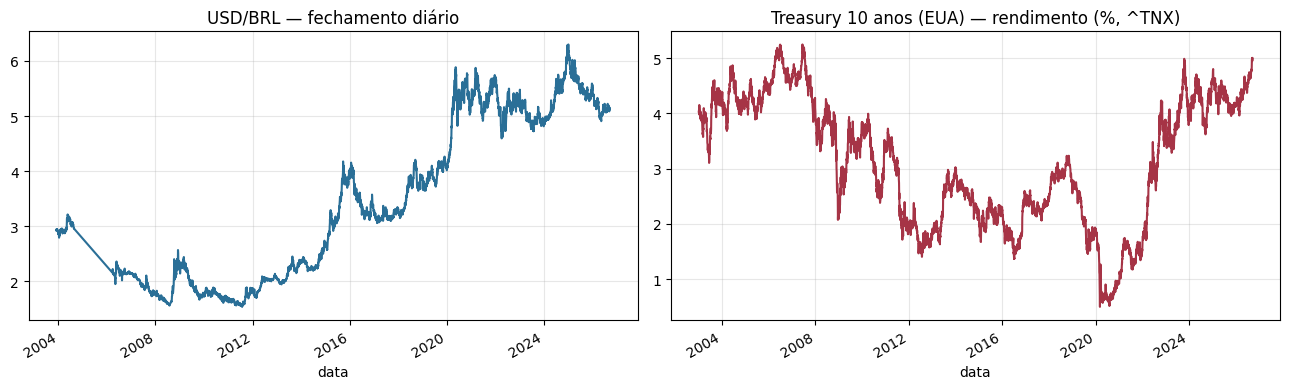

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

series_mercado["usdbrl"].set_index("data")["fechamento"].plot(ax=axes[0], color="#2a6f97")
axes[0].set_title("USD/BRL — fechamento diário")

series_mercado["tnx"].set_index("data")["fechamento"].plot(ax=axes[1], color="#a63446")
axes[1].set_title("Treasury 10 anos (EUA) — rendimento (%, ^TNX)")

plt.tight_layout()
plt.show()

## 5. Resumo da ingestão

Manifesto consolidado de tudo o que foi persistido nesta execução — serve como registro de proveniência (fonte, contagem de linhas, cobertura temporal, timestamp de coleta) e como o "no-op check" de reexecuções: rodar este notebook de novo dentro da janela de validade do manifesto não deve rebaixar as APIs.

In [13]:
resumo_bruto = resumo_manifesto(DIR_BRUTO)
resumo_referencia = resumo_manifesto(DIR_REFERENCIA)
pd.concat([resumo_bruto, resumo_referencia], ignore_index=True)

,dataset,fonte,linhas,coletado_em,data_minima,data_maxima
0,focus_ipca_mensal,Olinda OData (ExpectativaMercadoMensais / IPCA),99229,2026-09-19T08:17:24.214566+00:00,2006-01-02 00:00:00,2026-09-11 00:00:00
1,focus_selic,Olinda OData (ExpectativasMercadoSelic),65022,2026-09-19T08:21:08.050641+00:00,2006-01-02 00:00:00,2026-09-11 00:00:00
2,focus_top5_selic,Olinda OData (ExpectativasMercadoTop5Selic),64985,2026-09-19T08:21:35.129024+00:00,2006-01-02 00:00:00,2026-09-11 00:00:00
3,sgs_ipca_mensal,SGS/BCB (codigo 433),272,2026-09-19T08:23:32.618808+00:00,2004-01-01 00:00:00,2026-08-01 00:00:00
4,sgs_meta_selic,SGS/BCB (codigo 432),8298,2026-09-19T08:25:52.730182+00:00,2004-01-01 00:00:00,2026-09-19 00:00:00
5,sgs_selic_acum_mes_anualizada,SGS/BCB (codigo 4189),273,2026-09-19T08:25:55.443283+00:00,2004-01-01 00:00:00,2026-09-01 00:00:00
6,sgs_ibcbr,SGS/BCB (codigo 24364),271,2026-09-19T08:25:57.823057+00:00,2004-01-01 00:00:00,2026-07-01 00:00:00
7,sgs_icbr,SGS/BCB (codigo 27574),272,2026-09-19T08:26:00.502998+00:00,2004-01-01 00:00:00,2026-08-01 00:00:00
8,sgs_meta_inflacao,SGS/BCB (codigo 13521),23,2026-09-19T08:26:02.631970+00:00,2004-01-01 00:00:00,2026-01-01 00:00:00
9,mercado_usdbrl,yfinance (USDBRL=X),5498,2026-09-19T08:26:17.045150+00:00,2003-12-01 00:00:00,2026-09-18 00:00:00


### Próximo passo

Com os dados brutos persistidos, a **Etapa 2 (`02_transformacao.ipynb`)** constrói:
- a data de travamento da pesquisa (`data_travamento`) por `(período de referência, horizonte)`;
- os alvos `erro_focus` para IPCA (mensal) e Selic (por reunião);
- as features de momento, dispersão do consenso e regime, todas unidas via *merge_asof* respeitando a defasagem de publicação de cada série — o controle central de viés *look-ahead* do projeto.